# Data Collection

This notebook collects the price data used throughout the project and splits it into an in-sample period and an out-of-sample period. The split is set here, before any strategies are built or tested, so that the out-of-sample data stays untouched until the final evaluation. 

Functions are first developed within the notebook before being added to a separate .py file, which is then imported into future notebooks.

In [1]:
# Importing the necessary packages
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd

### Step 1: Importing the Data and Defining the Sample Periods

Daily price data for [NUMBER] assets (SPY, QQQ, IWM, TLT, GLD) is collected using Yahoo Finance. The same sample periods are applied to every asset. The in-sample period runs from [START] to [END], and the out-of-sample period runs from [START] to [END].

In [2]:
def get_data(ticker, start_date, end_date):
    data = yf.download(ticker, start=start_date, end=end_date, interval="1d", auto_adjust=True, multi_level_index=False)
    #data = data[['Open', 'Close']]
    return data

# Data visualization

### Plot 1: Daily Closing Prices (2006-2025)

The daily closing prices for each asset are plotted over the full sample period to check that the data downloaded correctly and to show how each asset behaved over the period. The dashed vertical line marks the split between the in-sample and out-of-sample periods.

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


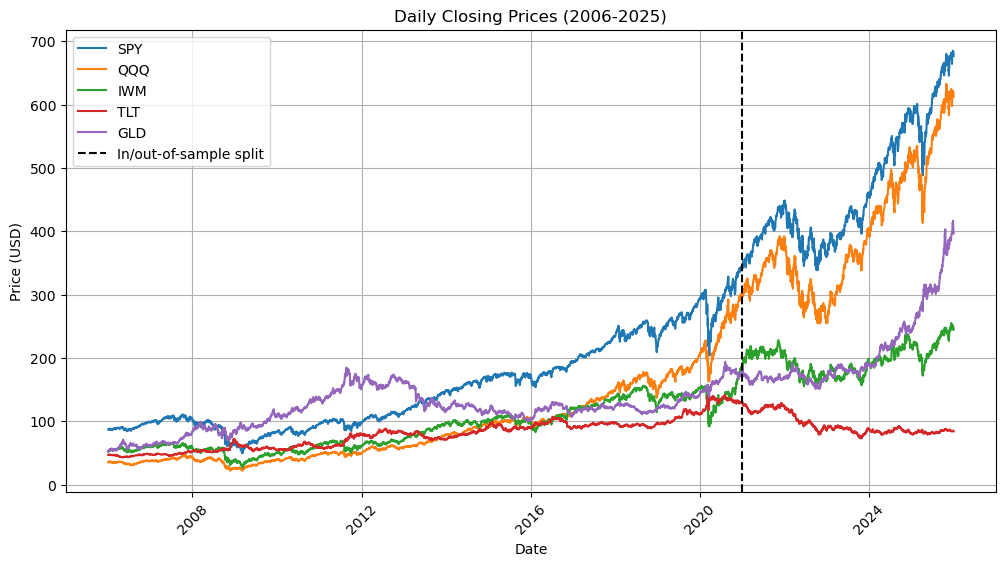

In [3]:
start_date = "2006-01-01"
end_date = "2026-01-01"
SPY_data = get_data("SPY", start_date, end_date)
QQQ_data = get_data("QQQ", start_date, end_date)
IWM_data = get_data("IWM", start_date, end_date)
TLT_data = get_data("TLT", start_date, end_date)
GLD_data = get_data("GLD", start_date, end_date)
dates = SPY_data.index
split_date = pd.Timestamp("2021-01-01")

plt.figure(figsize=(12,6))
plt.plot(dates, SPY_data['Close'])
plt.plot(dates, QQQ_data['Close'])
plt.plot(dates, IWM_data['Close'])
plt.plot(dates, TLT_data['Close'])
plt.plot(dates, GLD_data['Close'])
plt.axvline(split_date, linestyle="--", color="Black")
plt.title("Daily Closing Prices (2006-2025)")
plt.legend(["SPY", "QQQ", "IWM", "TLT", "GLD", "In/out-of-sample split"])
plt.xlabel("Date")
plt.xticks(rotation=45)
plt.ylabel("Price (USD)")
plt.grid(True)
plt.show()

### Plot 2: Cumulative Returns (2006–2025)

Because the assets trade at very different price levels, raw prices are difficult to compare directly. Each asset's cumulative return is calculated relative to its first closing price in the sample, so every asset starts at 0% and can be compared on the same scale. Prices are adjusted for dividends and splits, so these are total returns. The dashed vertical line marks the split between the in-sample and out-of-sample periods.

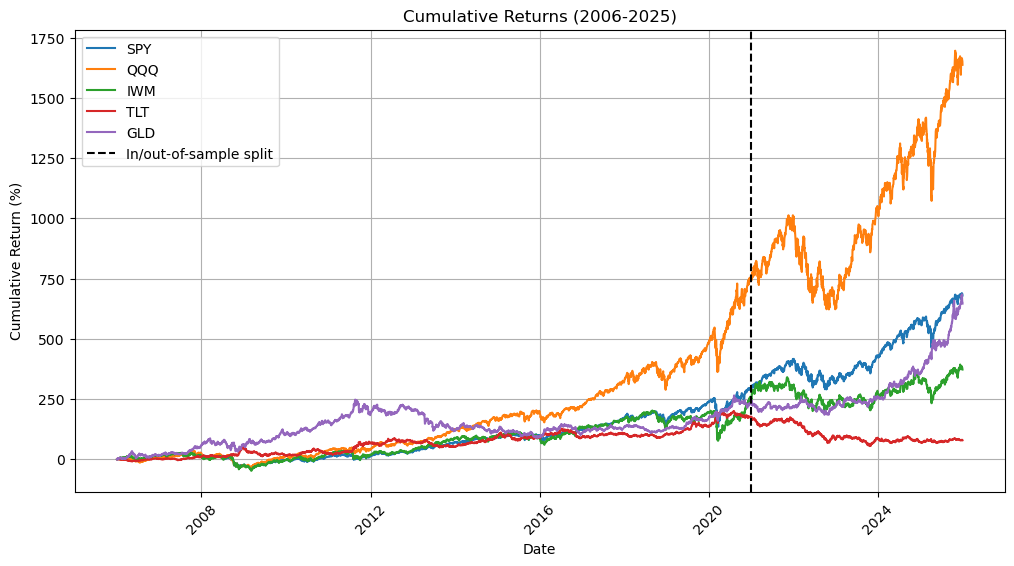

In [4]:
def ticker_growth(data):
    growth_to_date = []
    growth_to_date.append(0)
    for i in range(1, len(data)):
        percent_growth = 100 * (data['Close'].iloc[i] - data['Close'].iloc[0]) / data['Close'].iloc[0]
        growth_to_date.append(percent_growth)
    return growth_to_date

plt.figure(figsize=(12,6))
plt.plot(dates, ticker_growth(SPY_data))
plt.plot(dates, ticker_growth(QQQ_data))
plt.plot(dates, ticker_growth(IWM_data))
plt.plot(dates, ticker_growth(TLT_data))
plt.plot(dates, ticker_growth(GLD_data))
plt.axvline(split_date, linestyle="--", color="Black")
plt.title("Cumulative Returns (2006-2025)")
plt.legend(["SPY", "QQQ", "IWM", "TLT", "GLD", "In/out-of-sample split"])
plt.xlabel("Date")
plt.xticks(rotation=45)
plt.ylabel("Cumulative Return (%)")
plt.grid(True)
plt.show()